# Evolutionary modelling of precancerous epithelial tissue

The purpose of this practical is to get experience running simulations of Wright-Fisher and Moran process models. The different notebooks teach different skills and should be worked through in the order

1. Simple Models
    - Basic introduction to running and visualising simulations
    - Explore the differences between Wright-Fisher and Moran processes, and the influence of space on competition
2. Fitting Models
    - Working with observed data, perform parameter sweeps to estimate the best fitting parameters
    - Observe data that do and do not fit simple models well
3. Exploring competition and epistasis
    - Using parameters derived in (2) explore how mutations are expected to combine
    - Include epistatic relationships between mutations and explore the effects
      
The notebooks contain missing code and questions, which you are expected to complete to proceed. The purpose of the questions is to reinforce the learning associated with running the code- whilst there are no set answers, if you cannot answer them you need to engage with the teaching team.

## Testing your install

The following code should be run to confirm that your set up works.

In [1]:
# Import the Parameters class. This is used to set up all simulations
# Subsequent guides will go into more detail on the other parameter classes
from clone_competition_simulation import Parameters, PopulationParameters, TimeParameters, FitnessParameters

p = Parameters(
    algorithm='Moran',  # We will run a non-spatial Moran simulation. 
    times=TimeParameters(
        max_time=25,  # Run for 25 time units
        division_rate=1.4  # Set average division rate for all cells to 1.7 per time unit
    ), 
    population=PopulationParameters(  # Define the cell population
        initial_size_array=[100, 100, 100]  # There are three initial clones, with 100 cells in each
    ),
    fitness=FitnessParameters(  # Define the cell fitness
        initial_fitness_array=[1, 1.02, 1.04]    # Each clone has a different fitness value
    )
)

sim = p.get_simulator()
sim.run_sim()

Output()

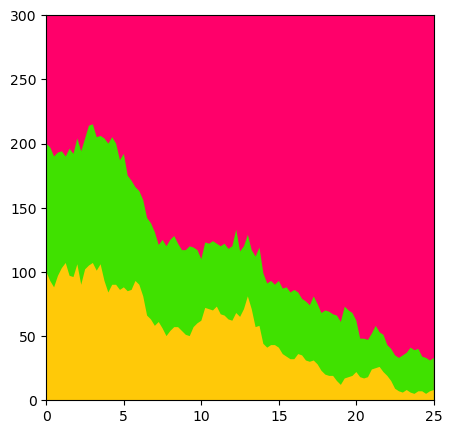

In [2]:
import matplotlib.pyplot as plt

sim.muller_plot(figsize=(5, 5))
plt.show()

## A note on software maintenance, large language models, and bugs

In this practical we are using a scientific library developed in the Hall group for simulating this type of system. This is developed and maintained by a single developer. This is typical for a lot of software development, particularly in scientific research where the initial development is conducted within a fixed time research project such as a PhD or post doctoral position, and is not funded to continue. This has the implication that bugs might exist in the code, and they may not be fixable on a useful timescale by the original developer. If the original developer is not currently using the code, they may never fix the issues for you.

If you're adopting other people code, you take responsibility for the outputs and should be proactive in fixing bugs yourself. This might include writing code to work around the bugs in your own scripts (for example, by using a monkey patch https://en.wikipedia.org/wiki/Monkey_patch), or forking the library and making the fixes yourself in the library itself. 

For small code bases it might be straightforward to read their code, make a fix, and keep working. For mature and sophisticated code bases (like the one in use here) making these edits may be a slow process of learning how the code works, finding the location of the bug, and then developing your workaround. 

Large language models can used in these situations to reduce the time taken to find and workaround bugs. It's important to remember that ultimately you take responsibility for the outputs, but taking the errors you find and prompting a tool such as Claude with the problem code, the error it gives, and the codebase (e.g. the github repository) can help you identify the problem in the code and propose workarounds. 

Always remember that LLM are stochastic, and can write faulty code. This could be an obvious fault that leads to the code not running, which you may in turn use the LLM to fix. It could also be a more subtle problem that does not lead to an error but undermines your analysis. This is a worse type of bug as it does not present itself immediately, and requires that you understand how the code you are using works.

It is *your* responsibilty to assess and ensure that the workarounds don't break anything else and you cannot reasonably blame the LLM you used. You can however study the fix and the justification given to take ownership and responsibility yourself. 

### LLM and new functions

The library includes several features for plotting simulations, reducing the barriers and difficulty to performing common visualisations. However visualisation is typically something you will want to customise as you explore the data and model dynamics, and its likely that you will want to redraw graphs in new styles to better represent some feature of interest. 

Historically, the only way to do this might have been to revisit the code that almost does what you want, and use it as a base to develop your own functions. Again LLM offer an opportunity to speed up this process. Libraries like matplotlib (a graph plotting tool used here) require effort to get the most out of them, and if you are not focused on matplotlib then learning all of the options may be a substantial time cost that you can avoid. More complex problems can also be addressed too, by specifying the problem you wish to tackle and allowing the LLM to select an approach and develop a function. 

This new code comes with all of the caveats that bug fixes by LLM do, with the additional complication that *you may not know what correct looks like*. As before, *you are responsible for the validity of your scientific outputs*. If you don't understand what you have done, then you will not be able to defend it if a problem is later found.

In this practical some plotting functions have been written by LLM, and part of the practical is about fixing a useful function with a bug generated by the LLM (non-intentionally). 